# 09 · Error analysis

This notebook examines the saved writer-independent CNN’s predictions on the supplied EMNIST test split. It summarizes performance by digit, visualizes confusion patterns, and inspects representative mistakes and their confidence. It does not retrain or change the model.

Notebook 08’s writer-grouped validation result measures performance on writers excluded from fitting. The supplied test split shares writer IDs with the original training split, so interpret this error analysis as describing errors on that provided test set.


In [10]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
)


from src.data import load_emnist
from src.preprocessing import preprocess_images


## Load the saved model and test data

Load the model created in notebook 08 and the same supplied test split. Keep the labels unchanged and apply the project preprocessing before prediction.


In [11]:
model = tf.keras.models.load_model("../models/cnn_writer_independent.keras")
_, _, writers_train, X_test, y_test, writers_test = load_emnist()
X_test = preprocess_images(X_test)

print("Test images:", X_test.shape)
print("Test labels:", y_test.shape)
print("Model output:", model.output_shape)
train_writer_set = set(writers_train)
test_writer_set = set(writers_test)
print("Writer IDs shared with original training split:", len(train_writer_set & test_writer_set))


Test images: (40000, 28, 28, 1)
Test labels: (40000,)
Model output: (None, 10)
Writer IDs shared with original training split: 3577


## Generate predictions

The model outputs one probability per digit. The predicted label is the digit with the highest probability; its probability is retained to examine confidence on correct and incorrect examples.


In [12]:
y_probability = model.predict(X_test, batch_size=128, verbose=1)
y_pred = np.argmax(y_probability, axis=1)
predicted_confidence = np.max(y_probability, axis=1)
correct = y_pred == y_test
misclassified = np.flatnonzero(~correct)

print(f"Correct predictions: {correct.sum():,} / {len(y_test):,}")
print(f"Misclassified:       {len(misclassified):,}")
print(f"Error rate:          {len(misclassified) / len(y_test):.4%}")


313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step
Correct predictions: 39,818 / 40,000
Misclassified:       182
Error rate:          0.4550%


## Performance by digit

The report shows precision, recall, and F1 for each digit. The bar graph makes per-digit recall easy to compare; lower recall means more examples of that true digit were assigned another label.


              precision    recall  f1-score   support

           0     0.9967    0.9965    0.9966      4000
           1     0.9987    0.9968    0.9977      4000
           2     0.9955    0.9922    0.9939      4000
           3     0.9938    0.9952    0.9945      4000
           4     0.9945    0.9950    0.9948      4000
           5     0.9977    0.9945    0.9961      4000
           6     0.9955    0.9982    0.9969      4000
           7     0.9960    0.9960    0.9960      4000
           8     0.9938    0.9950    0.9944      4000
           9     0.9923    0.9950    0.9936      4000

    accuracy                         0.9954     40000
   macro avg     0.9955    0.9954    0.9955     40000
weighted avg     0.9955    0.9954    0.9955     40000



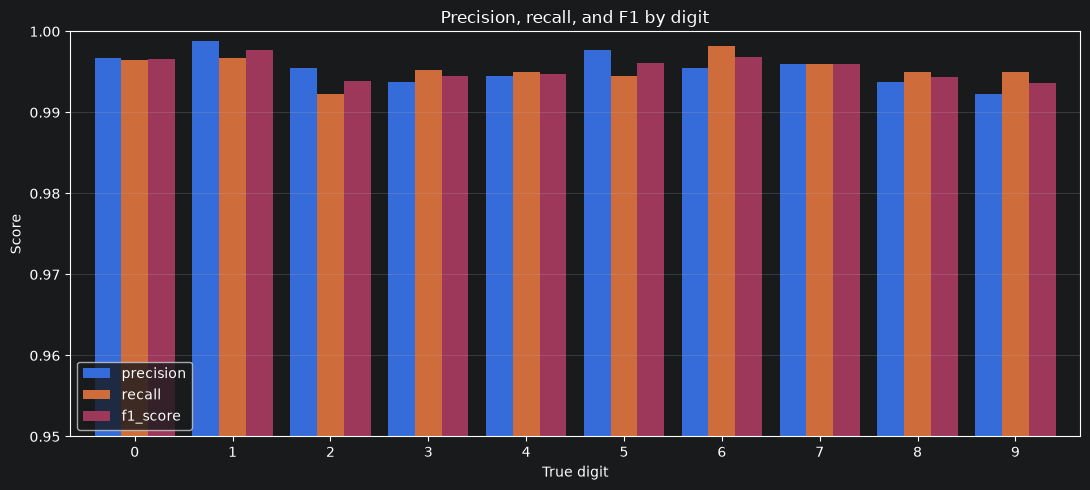

In [13]:
report = classification_report(y_test, y_pred, labels=np.arange(10), output_dict=True, zero_division=0)
per_digit = pd.DataFrame(
    [
        {
            "digit": digit,
            "precision": report[str(digit)]["precision"],
            "recall": report[str(digit)]["recall"],
            "f1_score": report[str(digit)]["f1-score"],
            "support": int(report[str(digit)]["support"]),
        }
        for digit in range(10)
    ]
).set_index("digit")

print(classification_report(y_test, y_pred, digits=4, zero_division=0))

ax = per_digit[["precision", "recall", "f1_score"]].plot(
    kind="bar", figsize=(11, 5), width=0.82
)
ax.set_xlabel("True digit")
ax.set_ylabel("Score")
ax.set_title("Precision, recall, and F1 by digit")
ax.set_ylim(0.95, 1.0)
ax.grid(axis="y", alpha=0.3)
ax.legend(loc="lower left")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()


## Inspect the confusion matrix

The normalized matrix reports the proportion of each true digit predicted as each class. The diagonal is correct classification; larger off-diagonal values show the most frequent confusions relative to each true digit.


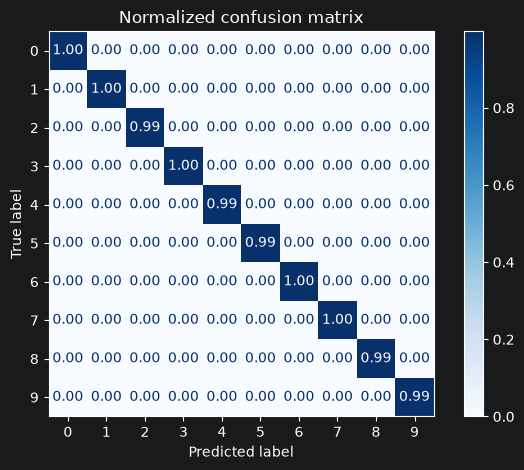

In [14]:
cm = confusion_matrix(y_test, y_pred, labels=np.arange(10), normalize="true")
display = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=np.arange(10),
)
display.plot(cmap="Blues", values_format=".2f", colorbar=True)
display.ax_.set_title("Normalized confusion matrix")
plt.tight_layout()
plt.show()


## Find the most common confusions

This graph ranks incorrect true-digit → predicted-digit pairs by count. It highlights which mistakes account for the largest share of errors and gives a focused set of examples to inspect next.


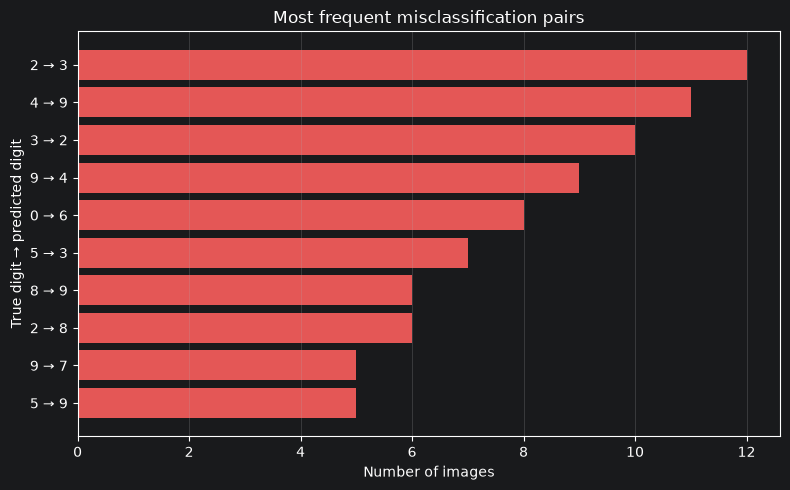

 true  predicted  count
    2          3     12
    4          9     11
    3          2     10
    9          4      9
    0          6      8
    5          3      7
    2          8      6
    8          9      6
    9          7      5
    5          9      5


In [15]:
error_pairs = pd.DataFrame({"true": y_test[misclassified], "predicted": y_pred[misclassified]})
pair_counts = (
    error_pairs.value_counts(["true", "predicted"])
    .rename("count")
    .reset_index()
    .sort_values("count", ascending=False)
)

if pair_counts.empty:
    print("No misclassifications on this test split.")
else:
    top_pairs = pair_counts.head(10).copy()
    top_pairs["pair"] = top_pairs.apply(
        lambda r: f"{int(r['true'])} → {int(r['predicted'])}", axis=1
    )
    top_pairs = top_pairs.sort_values("count")
    plt.figure(figsize=(8, 5))
    plt.barh(top_pairs["pair"], top_pairs["count"], color="#E45756")
    plt.xlabel("Number of images")
    plt.ylabel("True digit → predicted digit")
    plt.title("Most frequent misclassification pairs")
    plt.grid(axis="x", alpha=0.3)
    plt.tight_layout()
    plt.show()
    print(top_pairs[["true", "predicted", "count"]].sort_values("count", ascending=False).to_string(index=False))


## View representative mistakes

The montage shows up to 20 errors from the most frequent confusion pairs. Each title includes the true label, prediction, and predicted-class confidence. Use these examples to look for visual similarities or preprocessing issues; a few images alone do not establish a general cause.


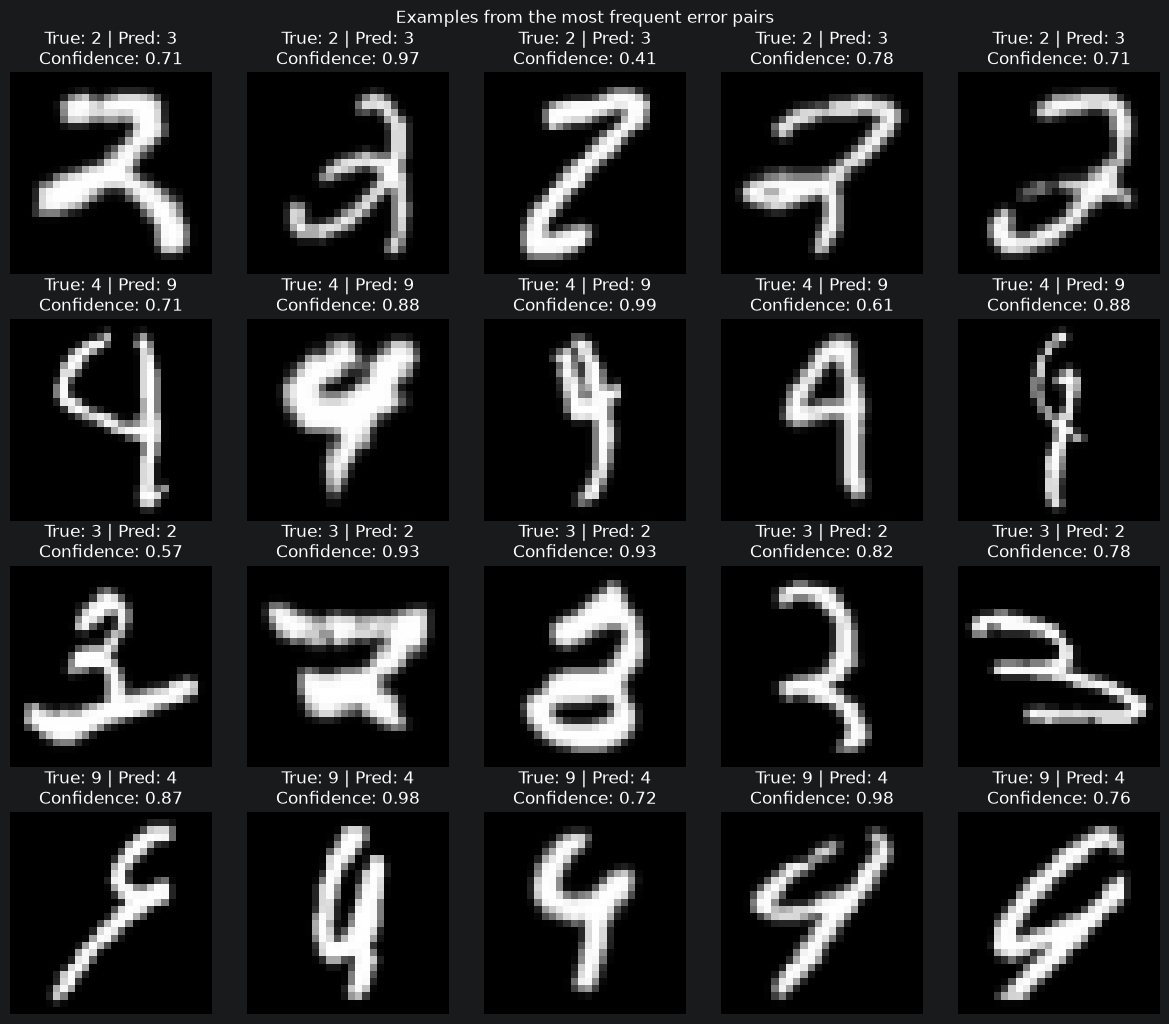

In [16]:
if len(misclassified) == 0:
    print("No errors to display.")
else:
    selected_indices = []
    for row in pair_counts.head(4).itertuples(index=False):
        pair_indices = np.flatnonzero((y_test == row.true) & (y_pred == row.predicted))
        selected_indices.extend(pair_indices[:5].tolist())
    selected_indices = selected_indices[:20]

    ncols = 5
    nrows = int(np.ceil(len(selected_indices) / ncols))
    fig, axes = plt.subplots(nrows, ncols, figsize=(12, 2.6 * nrows))
    axes = np.atleast_1d(axes).ravel()
    for ax, idx in zip(axes, selected_indices):
        ax.imshow(X_test[idx].squeeze(), cmap="gray")
        ax.set_title(
            f"True: {y_test[idx]} | Pred: {y_pred[idx]}\n"
            f"Confidence: {predicted_confidence[idx]:.2f}"
        )
        ax.axis("off")
    for ax in axes[len(selected_indices):]:
        ax.axis("off")
    fig.suptitle("Examples from the most frequent error pairs")
    plt.tight_layout()
    plt.show()


## Compare confidence on correct and incorrect predictions

A model can make mistakes with high confidence as well as low confidence. The distributions below compare the predicted-class probability for correct and incorrect cases; inspect the incorrect tail to identify confidently wrong predictions.


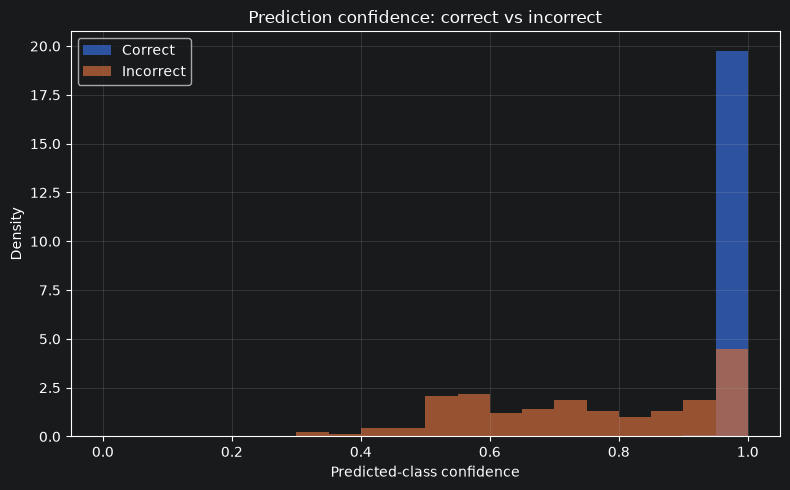

Mean confidence on correct predictions:   0.9974
Mean confidence on incorrect predictions: 0.7563


In [17]:
plt.figure(figsize=(8, 5))
plt.hist(predicted_confidence[correct], bins=np.linspace(0, 1, 21), alpha=0.7, label="Correct", density=True)
if np.any(~correct):
    plt.hist(predicted_confidence[~correct], bins=np.linspace(0, 1, 21), alpha=0.7, label="Incorrect", density=True)
plt.xlabel("Predicted-class confidence")
plt.ylabel("Density")
plt.title("Prediction confidence: correct vs incorrect")
plt.legend()
plt.grid(alpha=0.25)
plt.tight_layout()
plt.show()

if np.any(~correct):
    print(f"Mean confidence on correct predictions:   {predicted_confidence[correct].mean():.4f}")
    print(f"Mean confidence on incorrect predictions: {predicted_confidence[~correct].mean():.4f}")


## Results and interpretation

The saved run classified **39,818 of 40,000** test images correctly (**99.545% accuracy**) and made 182 errors. Each digit has 4,000 test examples. Digit 2 had the lowest recall (**99.22%**); digit 6 had the highest (**99.82%**).

The most frequent errors were **2 → 3** (12 images), **4 → 9** (11), and **3 → 2** (10). The model’s mean predicted-class probability was **0.9974** on correct predictions and **0.7563** on errors. This probability is a confidence score, not a calibration measurement.

These results describe the supplied test split. Its writer IDs overlap with the original training split, so this analysis does not establish performance on entirely unseen writers. Notebook 08 provides that writer-independent validation result.
